In [38]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image 



In [39]:
img=cv2.imread("images.jpg",cv2.IMREAD_GRAYSCALE)

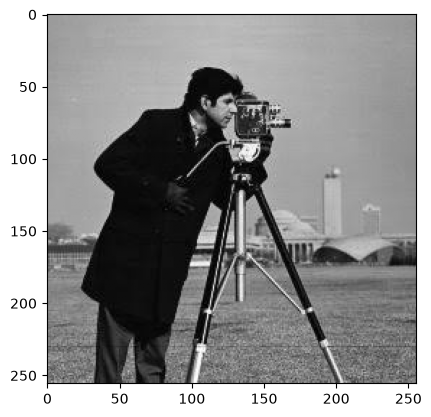

In [40]:
plt.imshow(img,cmap="gray")
plt.show()

In [41]:
noise=np.random.normal(0,25,img.shape)
gaussian_noisy=img.astype(np.float32)+noise
gaussian_noisy=np.clip(gaussian_noisy,0,255)
gaussian_noisy=gaussian_noisy.astype(np.uint8)

In [42]:
sp_noisy=img.copy()
num_pixels=img.size
num_salt=int(0.015 * num_pixels)
num_pepper=int(0.015 * num_pixels)

In [43]:
salt_rows=np.random.randint(0,img.shape[0],num_salt)
salt_cols=np.random.randint(0,img.shape[1],num_salt)
sp_noisy[salt_rows,salt_cols]=255

In [44]:
pepper_rows=np.random.randint(0,img.shape[0],num_pepper)
pepper_cols=np.random.randint(0,img.shape[1],num_pepper)
sp_noisy[salt_rows,salt_cols]=255

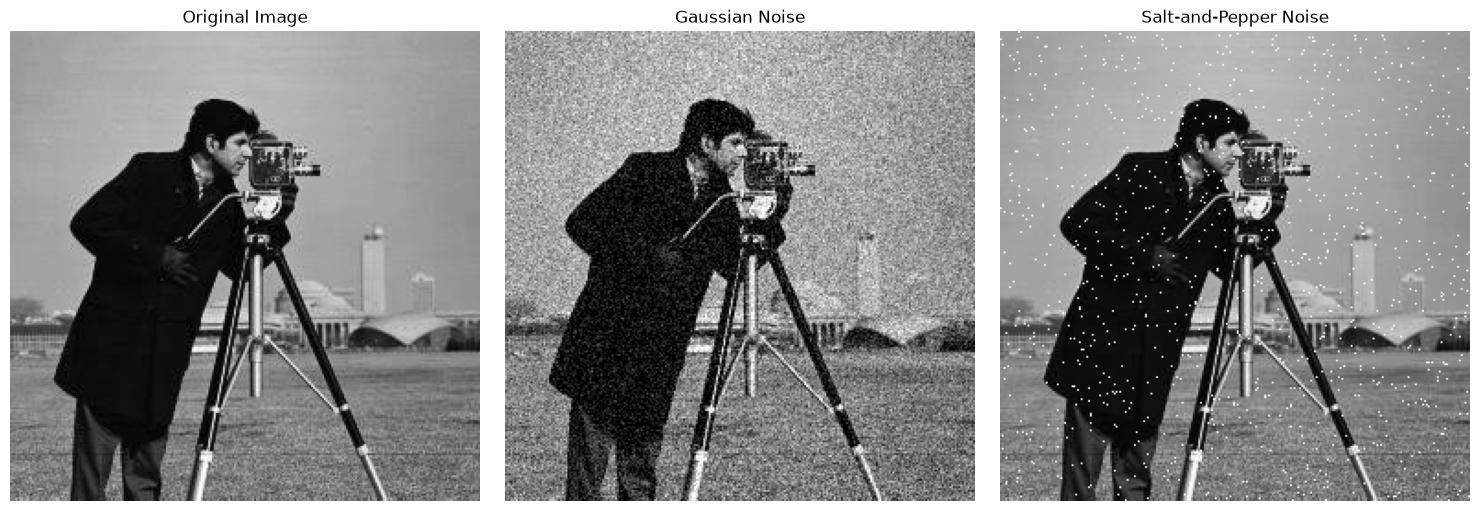

In [45]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy, cmap="gray")
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sp_noisy, cmap="gray")
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()



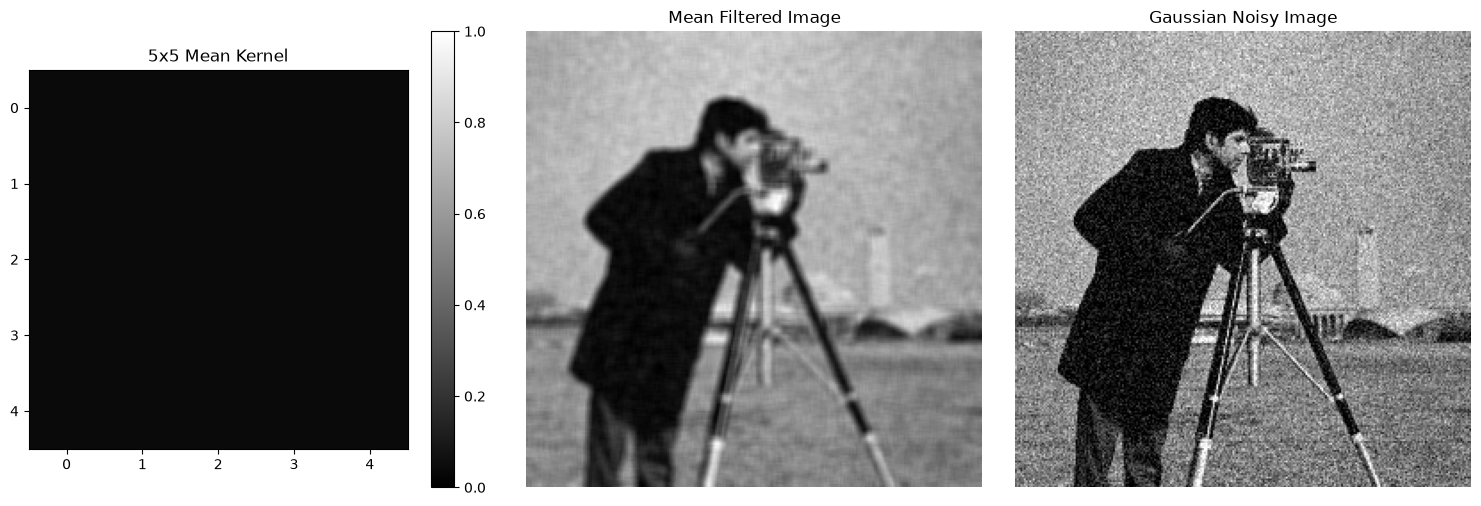

In [54]:
mean_kernel = np.ones((5, 5), dtype=np.float32) / 25

# Apply mean filter to Gaussian noisy image
mean_filtered_manual = cv2.filter2D(
    gaussian_noisy, -1, mean_kernel
)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mean_kernel, cmap="gray", vmin=0, vmax=1)
plt.title("5x5 Mean Kernel")
plt.colorbar()
plt.axis("on")

plt.subplot(1, 3, 2)
plt.imshow(mean_filtered_manual, cmap="gray")
plt.title("Mean Filtered Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_noisy, cmap="gray")
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [62]:
gaussian_1d=cv2.getGaussianKernel(5,sigma=1.5)
gaussian_2d_kernal=gaussian_1d @ gaussian_1d.T

In [64]:
gaussian_filtered_manual=cv2.filter2D(gaussian_noisy, -1, gaussian_2d_kernal)

In [65]:
gaussian_filtered_cv2 = cv2.GaussianBlur(
    gaussian_noisy, (5, 5), 1.5
)

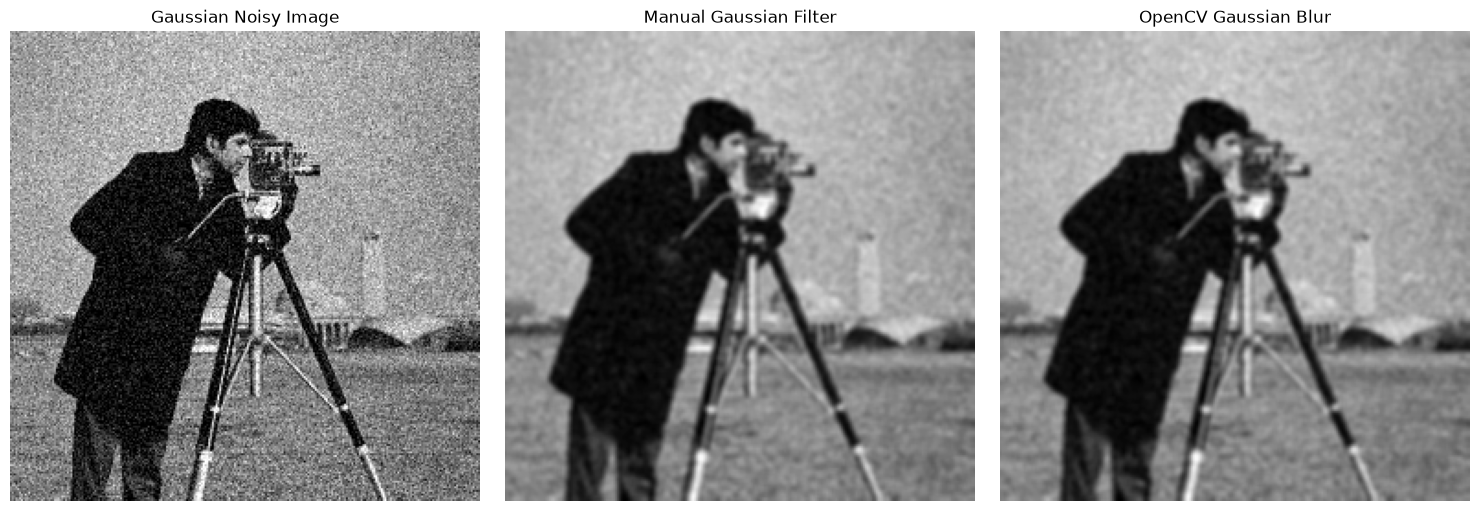

In [72]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(gaussian_noisy, cmap="gray")
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_filtered_manual, cmap="gray")
plt.title("Manual Gaussian Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_filtered_cv2, cmap="gray")
plt.title("OpenCV Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

## median filter

In [ ]:
#median filter

median_filtered_sp=cv2.medianBlur(sp_noisy,5)
mean_filtered_sp=cv2.blur(sp_noisy,(5,5))
gaussian_filtered_sp=cv2.GaussianBlur(sp_noisy,(5,5),sigmaX=1.5)

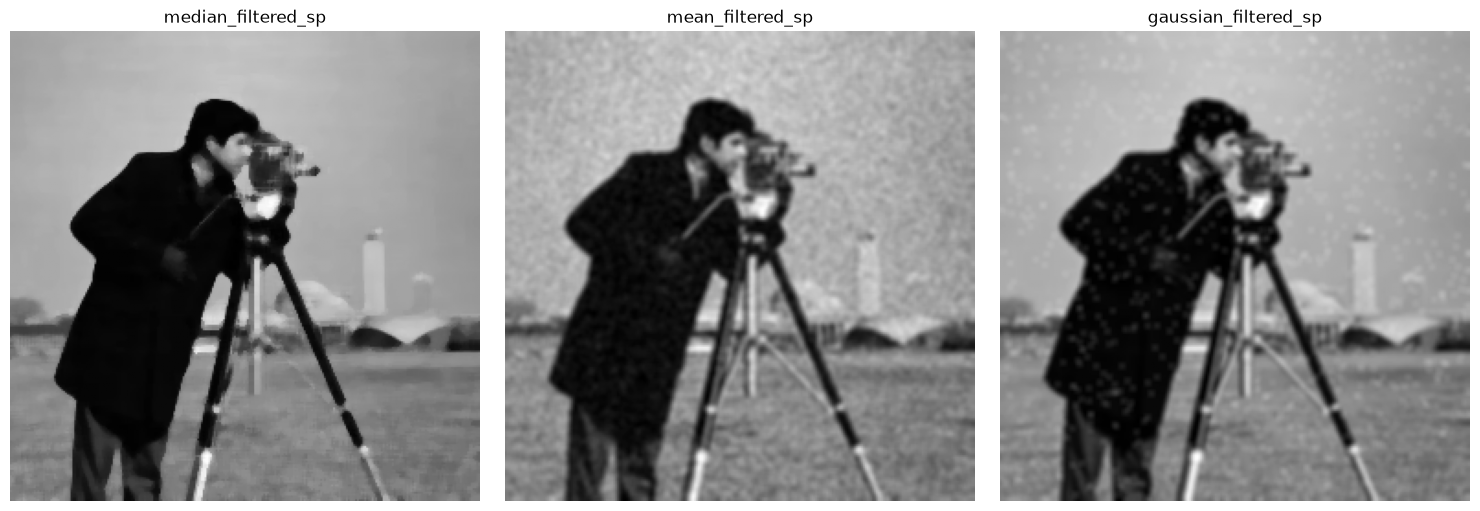

In [79]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(median_filtered_sp, cmap="gray")
plt.title("median_filtered_sp")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_filtered_manual, cmap="gray")
plt.title("mean_filtered_sp")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_filtered_sp, cmap="gray")
plt.title("gaussian_filtered_sp")
plt.axis("off")

plt.tight_layout()
plt.show()